# Training and explaining the model on C-MAPSS FD001

**Notebook 02 of the thesis project "Explainable Graph Neural Networks for Remaining Useful Life prediction".**

---

## What this notebook is for

Notebook 01 turned the raw NASA files into arrays. This one takes those arrays and does the remaining four things:

1. **builds** the network that Wen et al. (2026) describe in their Table 4,
2. **trains** it with the settings in their Table 6,
3. **scores** it with the four measures in their Section 3.3, and
4. **explains** it with the Shapley values of their Section 2.4.

As in notebook 01, every step has three parts: what it does, why it is done that way, and a check confirming it did what was intended.

## What you need before running it

The real NASA FD001 files in `data/raw/`, and PyTorch. Section 5 of `README.md` covers the download and section 4 covers PyTorch. Running the whole notebook takes about five minutes on a CPU, most of it two training runs.

## The one thing to keep in mind throughout

The per-sensor LSTM stage of the paper **can** now be built — `LSTMStage` in `models/temporal/` is the stage of its Section 2.2, fourteen dedicated networks, one per sensor — but it is **not what this notebook trains**. Section 3 builds both and shows what the stage costs and what it is worth; the run below uses the stand-in, because the stage is about thirteen times slower per epoch.

That decides which published row every number here may be set beside. **This notebook's results compare against the "ESTGNN w/o LSTM" row of the paper's ablation table (14.93 on FD001), never against its headline 11.78.** With `--temporal lstm` the headline becomes the right comparison instead — and even then only under the hidden size A-26 had to choose, which the paper never states.

See assumptions A-07, A-11 and A-26, and finding F-16, in `docs/ASSUMPTIONS.md`.

## 1. Setup

Each import line is a path through the project's folders: `thesis_gnn_rul_xai.models.estgnn` is the file `src/thesis_gnn_rul_xai/models/estgnn.py`. Section 9 of `README.md` explains the layout.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.data.pipeline import run_preprocessing
from thesis_gnn_rul_xai.evaluation import evaluate, prediction_error
from thesis_gnn_rul_xai.explain import (
    dynamic_shap,
    efficiency_error,
    mean_window_baseline,
    shap_summary,
    shap_values,
)
from thesis_gnn_rul_xai.graph.adjacency import (
    build_fully_connected_adjacency,
    normalize_adjacency,
)
from thesis_gnn_rul_xai.models import ESTGNN, LSTMStage, LastCycle
from thesis_gnn_rul_xai.training import TrainingConfig, evaluate_model, predict, train
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging()
plt.rcParams["figure.dpi"] = 110
print(f"PyTorch {torch.__version__}   CUDA available: {torch.cuda.is_available()}")

PyTorch 2.13.0+cpu   CUDA available: False


## 2. The data

Everything notebook 01 produced, in one call. Nothing new happens here; if any of it is unfamiliar, read notebook 01 first.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
prepared = run_preprocessing(config, data_dir=PROJECT_ROOT / "data" / "raw")
print()
display(prepared.summary())

14:04:53 | INFO    | thesis_gnn_rul_xai.data.loading | Loading FD001 from D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


14:04:53 | INFO    | thesis_gnn_rul_xai.data.loading | FD001 matches the published shape of the official release.


14:04:53 | INFO    | thesis_gnn_rul_xai.data.loading | Loaded FD001: 20631 training rows over 100 engines, 13096 test rows over 100 engines.


14:04:53 | WARNING | thesis_gnn_rul_xai.data.pipeline | The paper keeps sensor(s) ['P15'], but in this data they carry no usable variation. They are kept anyway, because the adjacency matrix is defined over the paper's fixed 14-sensor set. Report this observation rather than silently changing the selection.


14:04:53 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


14:04:53 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


... (4 outputs left out)

14:04:53 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 17731 window(s) of shape (14, 30) from 100 engine(s).


14:04:53 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 100 window(s) of shape (14, 30) from 100 engine(s).


14:04:53 | INFO    | thesis_gnn_rul_xai.data.pipeline | Preprocessing complete: 14459 training, 3272 validation, 100 test example(s).


,examples,engines,feature_shape,target_min,target_max
split,,,,,
train,14459,80,"(14, 30)",0.0,125.0
validation,3272,20,"(14, 30)",0.0,125.0
test,100,100,"(14, 30)",7.0,125.0


**Check.** Three things must hold before anything below is meaningful, and all three were established in notebook 01:

- the feature axis has 14 entries, one per graph node, in the paper's Table 3 order;
- no engine appears both in the training set and in the set held back from training — and with `config/fd001.yaml` nothing is held back at all, which is the arrangement the paper describes (A-06);
- each test engine contributes exactly one window, which is the single moment the official labels describe.

In [3]:
assert prepared.train.features.shape[1] == 14
assert set(prepared.train.units.tolist()).isdisjoint(prepared.validation.units.tolist())
assert len(prepared.test) == len(np.unique(prepared.test.units))

print(f"OK  {len(prepared.train):>6} training windows from {len(np.unique(prepared.train.units)):>3} engines")
if len(prepared.validation):
    print(f"OK  {len(prepared.validation):>6} held-back windows from {len(np.unique(prepared.validation.units)):>3} engines")
else:
    print("OK       0 held-back windows: this configuration holds nothing back (A-06),")
    print("         so every engine trains and no epoch is chosen over any other.")
print(f"OK  {len(prepared.test):>6} test windows from {len(np.unique(prepared.test.units)):>3} engines")
print()
print(f"One example has shape {prepared.train.features.shape[1:]}: "
      f"14 sensors, {prepared.train.features.shape[2]} cycles each.")
print("The pipeline hands over the whole window. How many numbers a sensor")
print("NODE carries is decided by the model, in section 3 below.")

OK   14459 training windows from  80 engines
OK    3272 held-back windows from  20 engines
OK     100 test windows from 100 engines

One example has shape (14, 30): 14 sensors, 30 cycles each.
The pipeline hands over the whole window. How many numbers a sensor
NODE carries is decided by the model, in section 3 below.


## 3. Step 9 — Build the network

### What a graph convolution does

Each of the three graph layers updates every sensor by mixing its own values with those of the sensors it is connected to, then applying a learned linear transformation:

$$H' = \mathrm{ReLU}\left(\hat{A} \, H \, W\right)$$

- $H$ holds the current features, one row per sensor.
- $\hat{A}$ is the sensor graph, fixed, with self-loops added and each edge divided by the degrees it joins. It is **not learned** — it is the engineering knowledge the paper builds in.
- $W$ is learned.

One layer lets a sensor see its direct neighbours. Three layers let it see three edges away.

### The architecture

Table 4 of the paper specifies every dimension, so nothing here is a guess. The cell below prints the network in the same form as that table, for checking side by side.

In [4]:
model = ESTGNN(
    prepared.adjacency_normalized,
    temporal=LastCycle(config.window_size),
    rul_max=config.rul_max,
)
print()
display(pd.DataFrame(model.layer_summary()))
print(f"Trainable parameters: {model.count_parameters():,}")

14:04:53 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


,layer,type,in,out,parameters,activation
0,Temporal,LastCycle,"(B, 14, 30)","(B, 14, 1)",0,-
1,Input,Node features,"(B, 14, 1)","(B, 14, 1)",0,-
2,GCN-1,GCN,"(B, 14, 1)","(B, 14, 32)",32,ReLU
3,GCN-2,GCN,"(B, 14, 32)","(B, 14, 64)",2048,ReLU
4,GCN-3,GCN,"(B, 14, 64)","(B, 14, 32)",2048,ReLU
5,Flatten,Tensor reshape,"(B, 14, 32)","(B, 448)",0,-
6,FC-1,Fully connected,"(B, 448)","(B, 128)",57472,ReLU
7,FC-2,Fully connected,"(B, 128)","(B, 1)",129,Sigmoid


Trainable parameters: 61,729


**Check.** With one number per sensor reaching the first graph layer — the shape Table 4 actually prints — the parameter count must match the weight matrices the paper lists: $W^{(1)}\in\mathbb{R}^{1\times32}$, $W^{(2)}\in\mathbb{R}^{32\times64}$, $W^{(3)}\in\mathbb{R}^{64\times32}$, $W_{fc1}\in\mathbb{R}^{448\times128}$, $W_{fc2}\in\mathbb{R}^{128\times1}$.

In [5]:
table4 = ESTGNN(prepared.adjacency_normalized,
                temporal=LastCycle(config.window_size),
                rul_max=config.rul_max)
expected = 1*32 + 32*64 + 64*32 + (448*128 + 128) + (128*1 + 1)
assert table4.count_parameters() == expected == 61_729
assert model.count_parameters() == expected
print(f"OK  Table 4 implies exactly {expected:,} parameters.")
print(f"    Ours has {model.count_parameters():,} - the same number, because each sensor node")
print(f"    carries one value, which is the [batch, 14, 1] input Table 4 prints (A-07).")

14:04:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


OK  Table 4 implies exactly 61,729 parameters.
    Ours has 61,729 - the same number, because each sensor node
    carries one value, which is the [batch, 14, 1] input Table 4 prints (A-07).


### What the graph lets the model see, and what it does not

The graph is fixed, so its shape bounds what any amount of training can express. Two facts about it are worth knowing before looking at any result.

**Some sensors are four edges apart.** With three layers, information travels at most three edges, so those pairs can never influence each other. The check below perturbs `P15` and confirms `W32` does not move at all, while `P15`'s direct neighbour `Nf` does.

**`T24` is the only articulation point.** Removing it would split the sensors into a fan group and a core group, so every message between those groups passes through it. That is a fact about the published graph, and a ready-made target for the graph-native explanation methods that come after SHAP.

In [6]:
order = list(prepared.sensor_symbols)

def three_graph_layers(windows: torch.Tensor) -> torch.Tensor:
    # Through the temporal stage first, exactly as forward() does. Reaching
    # into graph_layers with a raw window would hand them 30 numbers per node
    # and build the arrangement A-07 removed.
    hidden = model.temporal(windows)
    for layer in model.graph_layers:
        hidden = torch.relu(layer(hidden, model.adjacency))
    return hidden

base = torch.randn(1, 14, prepared.train.features.shape[2])
bumped = base.clone()
bumped[0, order.index("P15")] += 100.0

with torch.no_grad():
    before, after = three_graph_layers(base), three_graph_layers(bumped)

far = float((before[0, order.index("W32")] - after[0, order.index("W32")]).abs().max())
near = float((before[0, order.index("Nf")] - after[0, order.index("Nf")]).abs().max())
print(f"Perturbing P15 by +100, after three graph layers:")
print(f"  W32 (four edges away) changed by {far:.2e}   <- unreachable, exactly zero")
print(f"  Nf  (one edge away)   changed by {near:.2f}")
assert far == 0.0 and near > 0
print("\nOK  Message passing follows the sensor graph and nothing else.")

Perturbing P15 by +100, after three graph layers:


  W32 (four edges away) changed by 0.00e+00   <- unreachable, exactly zero
  Nf  (one edge away)   changed by 3.76

OK  Message passing follows the sensor graph and nothing else.


### The stage in front of the graph layers

Table 4 begins at `Input | Node features | [batch size,14,1]`. That is where the
paper's own architecture table starts, and it is worth noticing what sits
*before* it: nothing. The recurrent stage the paper describes in Section 2.2 has
**no row in Table 4 at all**.

So the network has three parts, not two, and the paper prints only the last two:

```
window of 30 cycles  ->  temporal stage  ->  graph layers  ->  dense layers
   (14, 30)                 (14, 1)            (14, 32)          one number
```

The pipeline hands over all thirty cycles. **What a sensor node carries is a
question about the model**, so it is answered in the model, by a named stage in
`models/temporal/`. Two of them matter here:

- **`LastCycle`** keeps the most recent reading and drops the other 29. It
  learns nothing. This is assumption **A-07**: it stands in for the paper's
  recurrent stage, and it is what every result in this project before
  2026-09-09 was produced with.
- **`LSTMStage`** is the paper's own stage: **fourteen dedicated recurrent
  networks, one per sensor**. Section 2.2 states that four times — *"Each
  sensor s ∈ {1, 2, …, n} is associated with a dedicated LSTM network"*, with
  Equation 7 indexing the hidden state by sensor. That part is a citation, not
  a choice. What the paper never states is the hidden size, the depth, or how
  a hidden state becomes the one number Table 4 wants, which is **A-26**.

Why this arrangement rather than letting the pipeline decide: with the width
read off the data, deleting one line of preprocessing silently made the first
graph weight matrix `(30, 32)` instead of `(1, 32)`. That happened on
2026-08-28, the model scored *better*, and two of this project's three
configuration comparisons reversed direction before anyone noticed the
architecture had changed. Read A-07 for the full story. The model now refuses
to build a stage that widens a node without learning anything across the
cycles, unless the caller asks for it in words.

In [7]:
# The same graph, the same everything else, two different temporal stages.
stand_in = ESTGNN(prepared.adjacency_normalized,
                  temporal=LastCycle(config.window_size),
                  rul_max=config.rul_max)
paper_stage = ESTGNN(prepared.adjacency_normalized,
                     temporal=LSTMStage(window_size=config.window_size,
                                        n_nodes=14, hidden_size=32),
                     rul_max=config.rul_max)

rows = []
for name, built in (("last_cycle (A-07 stand-in)", stand_in),
                    ("lstm, hidden 32 (the paper's)", paper_stage)):
    stage_size = sum(p.numel() for p in built.temporal.parameters())
    rows.append({
        "temporal stage": name,
        "numbers per node": built.in_features,
        "stage parameters": stage_size,
        "whole model": built.count_parameters(),
    })
display(pd.DataFrame(rows))

print("Both give the graph layers ONE number per sensor, so W(1) stays "
      "1 x 32 and")
print("Table 4 is untouched either way. What changes is where that number "
      "comes from.")
print()
print(f"The paper's stage costs "
      f"{paper_stage.count_parameters() - stand_in.count_parameters():,} extra "
      f"parameters,")
print(f"which brings the model to "
      f"{paper_stage.count_parameters() / stand_in.count_parameters():.2f} "
      f"times its previous size.")

display(pd.DataFrame(paper_stage.layer_summary()))
print("The first row is the stage. Every row below it is Table 4, unchanged.")

14:04:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


14:04:54 | INFO    | thesis_gnn_rul_xai.models.temporal | Built LSTM temporal stage: 14 cell(s) of hidden size 32 over a 30-cycle window, projected to 1 number(s) per sensor. 62753 parameters.


14:04:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 124482 trainable parameters.


,temporal stage,numbers per node,stage parameters,whole model
0,last_cycle (A-07 stand-in),1,0,61729
1,"lstm, hidden 32 (the paper's)",1,62753,124482


Both give the graph layers ONE number per sensor, so W(1) stays 1 x 32 and
Table 4 is untouched either way. What changes is where that number comes from.

The paper's stage costs 62,753 extra parameters,
which brings the model to 2.02 times its previous size.


,layer,type,in,out,parameters,activation
0,Temporal,LSTMStage,"(B, 14, 30)","(B, 14, 1)",62753,-
1,Input,Node features,"(B, 14, 1)","(B, 14, 1)",0,-
2,GCN-1,GCN,"(B, 14, 1)","(B, 14, 32)",32,ReLU
3,GCN-2,GCN,"(B, 14, 32)","(B, 14, 64)",2048,ReLU
4,GCN-3,GCN,"(B, 14, 64)","(B, 14, 32)",2048,ReLU
5,Flatten,Tensor reshape,"(B, 14, 32)","(B, 448)",0,-
6,FC-1,Fully connected,"(B, 448)","(B, 128)",57472,ReLU
7,FC-2,Fully connected,"(B, 128)","(B, 1)",129,Sigmoid


The first row is the stage. Every row below it is Table 4, unchanged.


**What the stage is worth, measured — and why that has two answers.** The
full comparison is finding **F-16** in `docs/ASSUMPTIONS.md`; the runs are in
`reports/`. Five seeds each, everything else identical, on the real FD001 test
engines, under two training procedures:

| Training procedure | `last_cycle` | `lstm`, hidden 32 | LSTM worth | paired *p* |
|---|---|---|---|---|
| **the paper's**: nothing held back, 200 epochs, final weights | 16.818 ± 0.157 | 16.052 ± 0.975 | **+0.77** | **0.117** |
| this project's: 20 % held back, best checkpoint restored | 16.496 ± 0.415 | 13.307 ± 0.532 | +3.19 | 0.0009 |
| *the paper's Table 11, FD001* | *14.93* | *11.78* | *+3.15* | — |

The two rows disagree, and the disagreement is the finding.

**With this project's procedure the stage looks worth 3.19 cycles**, close to
the 3.15 the paper's Table 11 prints. **With the paper's own procedure it is
worth 0.77, and five seeds cannot tell that apart from nothing.** Table 6 of
the paper states 200 epochs and it describes no held-out set, so the second row
is the one that follows the paper.

What separates them is restoring the best checkpoint. It is worth +2.75 cycles
to the recurrent model (*p* = 0.004) and only +0.32 to the stand-in
(*p* = 0.23). The recurrent model has twice the parameters, reaches its best
validation error between epochs 9 and 21, and gets much worse over the rest of
the 200; the smaller model barely moves. So checkpoint selection is not a
neutral detail here — it accounts for most of what the stage appeared to be
worth.

Three cautions belong with that table:

- **It does not show the paper selected checkpoints without saying so.** That
  would explain the agreement with Table 11, but the paper does not say, so it
  stays a suspicion.
- **A paired *p* across seeds tests only whether a difference is an artefact of
  initialisation.** The five seeds share one test set of 100 engines, so none
  of these numbers is uncertainty over engines — see the audit of 2026-09-08,
  D-8.
- **The over-training is inferred, not observed**: from where the best epochs
  fall and how much worse the final weights are. The per-epoch curves that
  would show it are built during training and never saved (the same audit,
  D-10).

Training the stage takes about thirteen times longer per epoch than the stand-in,
so the rest of this notebook uses `last_cycle`. Pass `--temporal lstm` to
`scripts/train.py` to train the other one.

## 4. Step 10 — Train

Table 6 of the paper gives Adam, 200 epochs, batch size 32, a learning rate falling from $10^{-3}$ to $10^{-4}$, and mean squared error. Two things it does not give are recorded as assumptions rather than hidden in the code: **how** the learning rate travels between those two values (A-17), and when to stop early (A-18).

`early_stopping_patience` is set below, but with this configuration it can never fire. Stopping early requires something to watch, and `config/fd001.yaml` holds no engines back, so all 200 epochs run and the weights you get back are the last epoch's. That is what the paper describes. Loading `config/fd001_validated.yaml` instead holds 20 % of the engines back and brings A-18 into play.

### Why the targets are divided by 125

The network ends in a sigmoid, so its output is between 0 and 1. A label measured in cycles could never be reached by such a layer. Targets are therefore divided by `rul_max` for training and predictions multiplied back, which is assumption A-13 and is forced rather than chosen.

It has one consequence worth stating: **the model cannot predict a remaining life above 125 for any input whatsoever.** That is the architectural fact assumption A-02 rests on.

In [8]:
training = TrainingConfig(seed=42, device="cpu")
print("Settings taken from Table 6:")
for key in ("epochs", "batch_size", "learning_rate", "final_learning_rate", "optimizer", "loss"):
    print(f"  {key:22s} {getattr(training, key)}")
print("\nSettings the paper does not give (see docs/ASSUMPTIONS.md):")
for key, note in (("lr_schedule", "A-17"), ("early_stopping_patience", "A-18")):
    print(f"  {key:22s} {getattr(training, key)}   ({note})")

Settings taken from Table 6:
  epochs                 200
  batch_size             32
  learning_rate          0.001
  final_learning_rate    0.0001
  optimizer              adam
  loss                   mse

Settings the paper does not give (see docs/ASSUMPTIONS.md):
  lr_schedule            step   (A-17)
  early_stopping_patience 20   (A-18)


In [9]:
torch.manual_seed(training.seed)
model = ESTGNN(
    prepared.adjacency_normalized,
    temporal=LastCycle(config.window_size),
    rul_max=config.rul_max,
)
history = train(model, prepared.train, prepared.validation, training)
print()
print(history.summary())

14:04:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


14:04:57 | INFO    | thesis_gnn_rul_xai.training.run | Training for up to 200 epoch(s) on 14459 window(s), batch size 32, learning rate 1.0e-03 -> 1.0e-04 (step schedule).


14:04:58 | INFO    | thesis_gnn_rul_xai.training.run | epoch    1/200  train 0.03644  validation 22.188 cycles  lr 1.00e-03


14:05:05 | INFO    | thesis_gnn_rul_xai.training.run | epoch   10/200  train 0.02825  validation 21.298 cycles  lr 1.00e-03


14:05:12 | INFO    | thesis_gnn_rul_xai.training.run | epoch   20/200  train 0.02801  validation 21.177 cycles  lr 1.00e-03


14:05:19 | INFO    | thesis_gnn_rul_xai.training.run | epoch   30/200  train 0.02775  validation 21.215 cycles  lr 1.00e-03


... (3 outputs left out)

14:05:46 | INFO    | thesis_gnn_rul_xai.training.run | epoch   70/200  train 0.02710  validation 21.248 cycles  lr 1.00e-03


14:05:47 | INFO    | thesis_gnn_rul_xai.training.run | Stopping at epoch 71: the validation error has not improved for 20 epoch(s). Restoring the weights from epoch 51.


14:05:47 | INFO    | thesis_gnn_rul_xai.training.run | Trained for 71 epoch(s) in 49.7s, ending on early stopping. At its best, epoch 51, the model was out by 20.821 flight cycles on the engines held back from training. It holds the weights from that epoch.



Trained for 71 epoch(s) in 49.7s, ending on early stopping. At its best, epoch 51, the model was out by 20.821 flight cycles on the engines held back from training. It holds the weights from that epoch.


### The learning curve

Only the training loss is drawn, because nothing was held back and so nothing was measured between epochs. The loss is on the normalised scale the network sees, not in flight cycles: the targets were divided by 125 on the way in.

Falling training loss on its own says only that the model is fitting the engines it was shown. It cannot tell you whether that fit generalises — for that you need engines the model never saw, which is what section 5 uses the test set for. If you load `config/fd001_validated.yaml`, this cell draws a second panel with the error on the held-back engines and marks the epoch whose weights were kept.

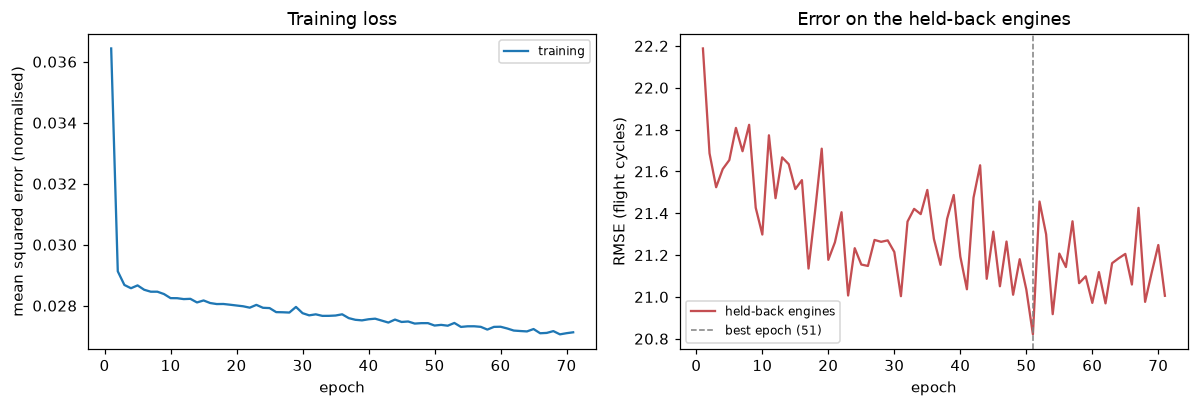

In [10]:
# The second panel exists only when engines were held back. With the default
# configuration nothing is, so there is no per-epoch error to draw.
held_back = "validation_rmse_cycles" in history.epochs.columns

fig, axes = plt.subplots(1, 2 if held_back else 1,
                         figsize=(11 if held_back else 6, 3.8), squeeze=False)
axes = axes[0]

axes[0].plot(history.epochs["epoch"], history.epochs["train_loss"], label="training")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mean squared error (normalised)")
axes[0].set_title("Training loss"); axes[0].legend(fontsize=8)

if held_back:
    axes[1].plot(history.epochs["epoch"], history.epochs["validation_rmse_cycles"],
                 color="#C44E52", label="held-back engines")
    axes[1].axvline(history.best_epoch, color="grey", linestyle="--", linewidth=1,
                    label=f"best epoch ({history.best_epoch})")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("RMSE (flight cycles)")
    axes[1].set_title("Error on the held-back engines"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()

**A warning for anyone who switches to the validated configuration.** The error on held-back engines is *not* comparable with the test error below, and the gap between the two means nothing about the model. They weight their engines completely differently: the held-back set keeps every window of its 20 engines, so one unusual engine contributing 240 windows can move the figure, while each of the 100 test engines contributes exactly one window and is worth exactly one per cent.

Error on held-back engines is the right signal for deciding when to stop training and for comparing two settings, because both are relative judgements against a fixed set. It is the wrong number to publish. See assumption A-06.

## 5. Step 11 — Score

Four measures, all defined in Section 3.3 of the paper, all computed over the 100 test engines from one prediction each. With `d = ŷ - y` the error in cycles:

| Measure | Formula | Direction |
|---|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum d^2}$ | lower is better |
| NASA score | $\sum s$, with $s = e^{-d/13}-1$ if $d<0$, else $e^{d/10}-1$ | lower is better |
| R² | $1 - \sum(\hat{y}-y)^2 / \sum(y-\bar{y})^2$ | higher is better, 1 is perfect |
| ASUE | $\frac{1}{N_{under}}\sum \max(0,\, y-\hat{y})$ | lower is better |

The score is asymmetric on purpose: the divisor 10 for a late prediction is smaller than the 13 for an early one, so the same error costs more when the model claimed more life than the engine had. **The paper's Equations 20 and 21 contradict each other about which direction that is**; the convention used here is the one its own prose describes and the one the 2008 challenge defines. See assumption A-15.

In [11]:
result = evaluate_model(model, prepared.test)
print("FD001 test set, one prediction per engine, single seed:\n")
for key, label in (("rmse", "RMSE"), ("score", "NASA score"), ("r2", "R-squared"), ("asue", "ASUE")):
    print(f"  {label:12s} {result[key]:9.3f}")
print(f"\n  engines       {result['n_engines']:9d}")
print(f"  optimistic on {result['n_late']:9d}  (the dangerous direction)")
print(f"  mean error    {result['mean_error']:+9.3f}  cycles")

FD001 test set, one prediction per engine, single seed:

  RMSE            16.695
  NASA score     580.398
  R-squared        0.826
  ASUE            12.253

  engines             100
  optimistic on        53  (the dangerous direction)
  mean error       +1.158  cycles


### How that compares with the paper

Table 11 of the paper reports **RMSE only** for its ablations, so `w/o LSTM` has no published score, R² or ASUE. The single comparable number is its FD001 RMSE of **14.93**.

In [12]:
comparison = pd.DataFrame([
    {"source": "this notebook (1 seed)", "RMSE": round(result["rmse"], 2),
     "NASA score": round(result["score"], 1), "R2": round(result["r2"], 3),
     "ASUE": round(result["asue"], 2)},
    {"source": "paper, ESTGNN w/o LSTM", "RMSE": 14.93,
     "NASA score": None, "R2": None, "ASUE": None},
    {"source": "paper, ESTGNN full", "RMSE": 11.78,
     "NASA score": 278.6, "R2": 0.921, "ASUE": 8.312},
])
display(comparison)
print("The comparable row is 'w/o LSTM', because this run trains without")
print("the stage (A-11). The full model's numbers are shown only for scale:")
print("no claim about them can be made from THIS run. F-16 records what")
print("happens when the stage is trained, over five seeds.")

,source,RMSE,NASA score,R2,ASUE
0,this notebook (1 seed),16.69,580.4,0.826,12.250
1,"paper, ESTGNN w/o LSTM",14.93,NaN,NaN,NaN
2,"paper, ESTGNN full",11.78,278.6,0.921,8.312


The comparable row is 'w/o LSTM', because this run trains without
the stage (A-11). The full model's numbers are shown only for scale:
no claim about them can be made from THIS run. F-16 records what
happens when the stage is trained, over five seeds.


**One seed is not evidence.** The figure above comes from a single run and will move with the seed. The result this project reports is the mean over five seeds, which `scripts/train.py --seeds 5` produces. Section 8 of `README.md` records it for the configuration this notebook runs — z-score scaling, row normalisation, nothing held back:

```
RMSE 16.69 +/- 0.33    score 613    R2 0.826    ASUE 11.64
```

That is **worse** than the paper's 14.93 for the same ablation row, and the project does not claim to have reproduced it. `docs/ASSUMPTIONS.md` records why the two differ. The largest single cause is measured: the paper never describes how it scales its inputs at all, so that step is substituted from another paper (A-03), and finding F-10 attributes most of the remaining gap to exactly that substitution.

Capping the test labels at 125 (A-02) moves our number in our favour and has to be stated whenever it is set beside a published one.

### Predicted against true, engine by engine

This is the analogue of Fig. 8 in the paper. The left panel plots one point per test engine; the right shows how the errors are distributed, split into the safe direction and the dangerous one.

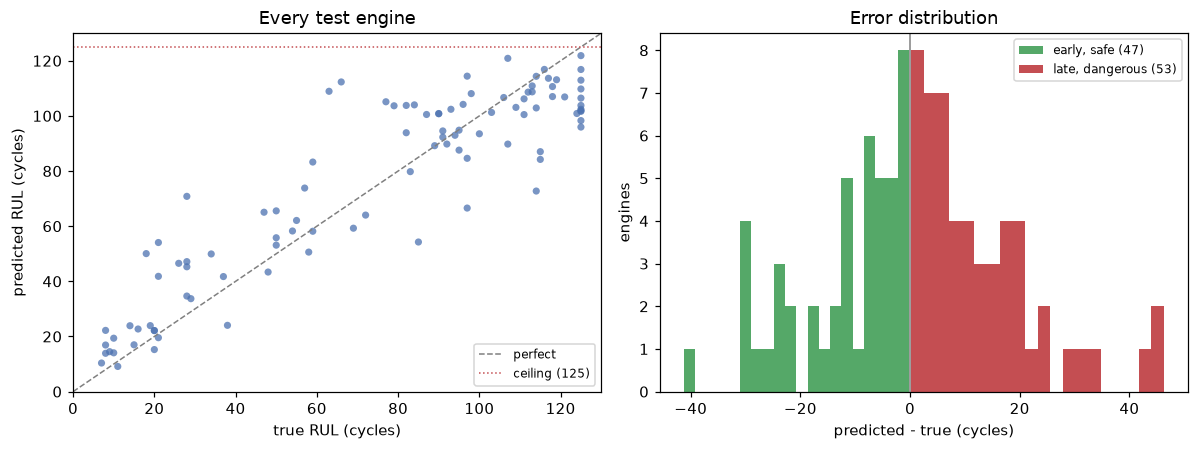

Nothing can sit above the dotted line at 125: the sigmoid output makes it
impossible. That is why assumption A-02 caps the test labels as well.


In [13]:
truth = prepared.test.targets.astype(float)
guess = predict(model, prepared.test)
error = prediction_error(truth, guess)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(truth, guess, s=22, alpha=0.75, color="#4C72B0", edgecolor="none")
lims = [0, config.rul_max + 5]
axes[0].plot(lims, lims, color="grey", linestyle="--", linewidth=1, label="perfect")
axes[0].axhline(config.rul_max, color="#C44E52", linestyle=":", linewidth=1,
                label=f"ceiling ({config.rul_max})")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("true RUL (cycles)"); axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].set_title("Every test engine"); axes[0].legend(fontsize=8)

axes[1].hist(error[error < 0], bins=20, color="#55A868", label=f"early, safe ({int((error<0).sum())})")
axes[1].hist(error[error >= 0], bins=20, color="#C44E52", label=f"late, dangerous ({int((error>=0).sum())})")
axes[1].axvline(0, color="grey", linewidth=1)
axes[1].set_xlabel("predicted - true (cycles)"); axes[1].set_ylabel("engines")
axes[1].set_title("Error distribution"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()
print("Nothing can sit above the dotted line at 125: the sigmoid output makes it")
print("impossible. That is why assumption A-02 caps the test labels as well.")

In [14]:
assert guess.max() <= config.rul_max + 1e-6
print(f"OK  The largest prediction is {guess.max():.2f}, and the ceiling is {config.rul_max}.")

OK  The largest prediction is 121.85, and the ceiling is 125.


## 6. Does the physics graph actually earn its place?

The paper builds its adjacency matrix by hand from engineering knowledge. The way to find out whether that helps is to replace it with a graph carrying no knowledge at all — every sensor connected to every other — and change nothing else. That is the paper's "without physics prior" ablation, though it never says what replaces the matrix; a complete graph is the reading used here, recorded as assumption A-19.

In [15]:
complete, _ = build_fully_connected_adjacency(14)
torch.manual_seed(training.seed)
ablation = ESTGNN(
    normalize_adjacency(complete),
    temporal=LastCycle(config.window_size),
    rul_max=config.rul_max,
)
ablation_history = train(ablation, prepared.train, prepared.validation, training)
ablation_result = evaluate_model(ablation, prepared.test)
print()
display(pd.DataFrame([
    {"sensor graph": "physics (paper's Table 3)", **{k: round(result[k], 3) for k in ("rmse","score","r2","asue")}},
    {"sensor graph": "fully connected (A-19)",   **{k: round(ablation_result[k], 3) for k in ("rmse","score","r2","asue")}},
]))
print(f"Removing the physics prior costs {ablation_result['rmse'] - result['rmse']:+.2f} cycles of RMSE here.")

14:05:48 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


14:05:48 | INFO    | thesis_gnn_rul_xai.training.run | Training for up to 200 epoch(s) on 14459 window(s), batch size 32, learning rate 1.0e-03 -> 1.0e-04 (step schedule).


14:05:48 | INFO    | thesis_gnn_rul_xai.training.run | epoch    1/200  train 0.03876  validation 22.829 cycles  lr 1.00e-03


14:05:54 | INFO    | thesis_gnn_rul_xai.training.run | epoch   10/200  train 0.03180  validation 22.867 cycles  lr 1.00e-03


14:06:01 | INFO    | thesis_gnn_rul_xai.training.run | epoch   20/200  train 0.03176  validation 22.893 cycles  lr 1.00e-03


14:06:08 | INFO    | thesis_gnn_rul_xai.training.run | epoch   30/200  train 0.03179  validation 22.841 cycles  lr 1.00e-03


... (2 outputs left out)

14:06:24 | INFO    | thesis_gnn_rul_xai.training.run | Stopping at epoch 51: the validation error has not improved for 20 epoch(s). Restoring the weights from epoch 31.


14:06:24 | INFO    | thesis_gnn_rul_xai.training.run | Trained for 51 epoch(s) in 35.8s, ending on early stopping. At its best, epoch 31, the model was out by 22.700 flight cycles on the engines held back from training. It holds the weights from that epoch.


,sensor graph,rmse,score,r2,asue
0,physics (paper's Table 3),16.695,580.398,0.826,12.253
1,fully connected (A-19),18.820,723.413,0.779,14.063


Removing the physics prior costs +2.13 cycles of RMSE here.


**This does not reproduce the paper's ablation, and the way it fails is the more interesting result.**

The single seed above is not evidence on its own, but it is no longer all there is. Measured over five seeds under exactly this configuration, removing the physics prior costs **2.52 cycles of RMSE**, paired `t = 17.9, p = 0.000057`, with every one of the five seeds worse without it. The run above is seed 42, whose cost was 2.367 — the middle of that range.

The paper reports the same ablation costing **0.56** cycles and calls it the smallest of the three components it tests. So this project measures the physics prior as worth over four times what the paper does.

**That number has now reversed twice, and the instability is the finding.** F-04 in `docs/ASSUMPTIONS.md` records all three attempts:

| Configuration | cost of removing the physics prior | p |
|---|---|---|
| current default — z-score, nothing held back | **+2.520** | 0.000057 |
| min-max, symmetric, 20 % held back | +0.044 | 0.913 |
| the withdrawn `window` mode | +5.7 | — |

Nothing about the graph changed between those rows. What changed was the input scaling and the split — neither of which the paper specifies. An ablation is normally reported as a property of an architecture; these measurements say it is a property of the architecture *and* the preprocessing, and the paper gives only the first.

That makes the paper's own ablation table unreproducible in principle rather than merely in practice, which is a stronger statement than "our number differs from theirs". Note also what cannot be concluded: two things changed between the zero result and this one, so these runs do not isolate which caused the reversal, and F-04 declines to guess.

## 7. Step 12 — Explain

### What a Shapley value is

Fourteen sensors together produced one number. Asking how much each contributed has no obvious answer, because they are not independent: removing one changes what the others are worth.

Cooperative game theory answers it. Build the group one sensor at a time in some order; each time a sensor joins, the prediction moves, and that move is its contribution *in that order*. Average over every possible order. That average is its **Shapley value**, and it is the only division of credit satisfying a short list of fairness conditions at once:

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\Big(f(S \cup \{i\}) - f(S)\Big)$$

which is Equation 15 of the paper.

### Why this implementation is exact, and most are not

The sum runs over every subset of the other sensors. With 14 sensors that is $2^{14} = 16{,}384$ subsets — small enough to simply enumerate. Most SHAP work cannot do this and must approximate by sampling. **Here no approximation is used**, so a disagreement with the paper can never be blamed on sampling noise.

### What "removing a sensor" means

Equation 15 needs $f(S)$, "the prediction when only sensors in $S$ are considered". A trained network cannot take thirteen inputs, so a sensor is never removed — it is **replaced** by a stand-in, and the choice decides what the numbers mean. The paper does not say what it uses. Here it is that sensor's average training window: "this sensor is behaving typically". Substituting zero would be far worse, because after min-max scaling zero is a sensor's *lowest reading ever recorded*. See assumption A-20.

In [16]:
baseline = mean_window_baseline(prepared.train)
one = shap_values(model, prepared.test.features[0], baseline)
print(f"Baseline shape {baseline.shape}, one Shapley value per sensor: {one.shape}")
print(f"Each of these came from {2**14:,} model evaluations, enumerated exactly.")

Baseline shape (14, 30), one Shapley value per sensor: (14,)
Each of these came from 16,384 model evaluations, enumerated exactly.


**The check that matters.** Shapley values must *add up*: the fourteen contributions plus the baseline prediction must equal the actual prediction, exactly. This is called **efficiency**, it is Equation 14 of the paper, and it is what separates a real attribution from a plausible-looking ranking. If it fails, the numbers are wrong however sensible they look.

In [17]:
with torch.no_grad():
    fx = float(model.predict_cycles(torch.from_numpy(prepared.test.features[:1])).item())
    fb = float(model.predict_cycles(torch.from_numpy(baseline[None])).item())

print(f"  f(x)                {fx:12.6f} cycles")
print(f"  f(baseline)         {fb:12.6f}")
print(f"  sum of SHAP values  {one.sum():12.6f}")
print(f"  f(x) - f(baseline)  {fx - fb:12.6f}")
err = efficiency_error(model, prepared.test.features[0], baseline, one)
print(f"\n  largest violation   {err:.3e} cycles")
assert err < 1e-4
print("\nOK  Efficiency holds to floating-point precision. These are Shapley values.")

  f(x)                  108.618858 cycles
  f(baseline)            91.885475
  sum of SHAP values     16.733383
  f(x) - f(baseline)     16.733383

  largest violation   3.553e-15 cycles

OK  Efficiency holds to floating-point precision. These are Shapley values.


### Dynamic: the same calculation at every cycle

Equation 16 of the paper is Equation 15 applied to the window ending at each cycle in turn. One engine that ran for 270 cycles yields 240 windows, so it yields 240 sets of 14 Shapley values — a picture of how the model's attention moved as the engine wore out. That is what the paper's Table 12 reports and its Fig. 10 draws.

In [18]:
# A trajectory needs every window of one engine. The test set keeps only the
# last window of each, so it cannot show one. Use the held-back engines when
# there are any, and the training engines otherwise -- which is the default,
# since this configuration holds nothing back.
source = prepared.validation if len(prepared.validation) else prepared.train
units, counts = np.unique(source.units, return_counts=True)
engine = int(units[np.argmax(counts)])

attribution = dynamic_shap(
    model, source, baseline, unit=engine, symbols=prepared.sensor_symbols
)
print()
print(f"Engine {engine}: {len(attribution)} windows x {2**14:,} coalitions each.")
display(attribution.head(3))

14:06:24 | INFO    | thesis_gnn_rul_xai.explain.shap | Explaining engine 5: 240 window(s), 16384 coalitions each, 3932160 model evaluations in total.



Engine 5: 240 windows x 16,384 coalitions each.


,end_cycle,rul,predicted,baseline,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
0,30,125.0,121.628197,91.885475,2.906775,14.060902,7.330121,10.702540,-9.235140,3.442031,0.526567,6.095552,-9.475274,2.936896,2.941237,7.989037,-4.348115,-6.130408
1,31,125.0,120.150742,91.885475,7.077506,13.242050,6.481755,6.432806,-9.280342,4.233091,0.640475,10.202657,-9.523121,3.549372,3.759516,11.280623,-11.109400,-8.721720
2,32,125.0,119.029518,91.885475,5.909979,11.436672,7.328706,3.226268,-7.563877,4.184541,2.103652,6.402099,-8.453725,4.452793,3.885480,13.890067,-10.970307,-8.688305


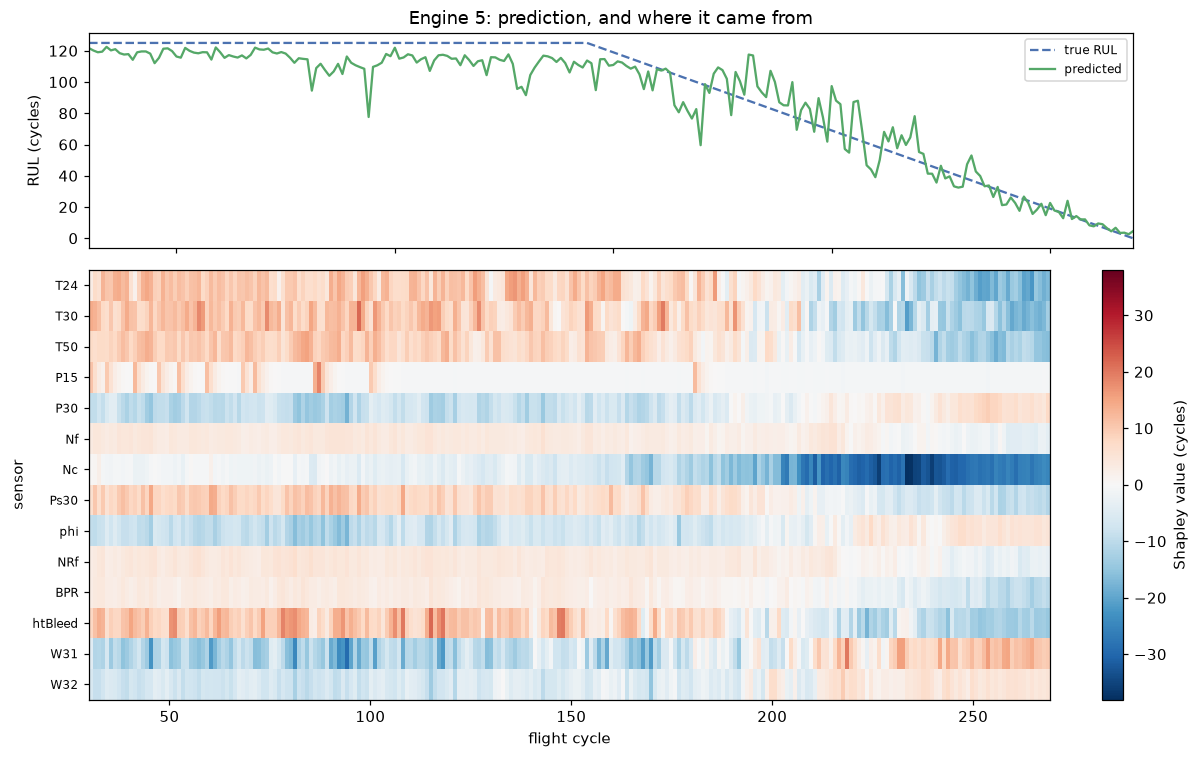

Red pushed the predicted life up, blue pushed it down. Notice the whole
picture inverting near the end of life, as the model switches from
'this engine is healthy' to 'this engine is nearly finished'.


In [19]:
sensors = list(prepared.sensor_symbols)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2]})

axes[0].plot(attribution["end_cycle"], attribution["rul"], label="true RUL",
             color="#4C72B0", linestyle="--")
axes[0].plot(attribution["end_cycle"], attribution["predicted"], label="predicted",
             color="#55A868")
axes[0].set_ylabel("RUL (cycles)"); axes[0].legend(fontsize=8)
axes[0].set_title(f"Engine {engine}: prediction, and where it came from")

image = axes[1].imshow(
    attribution[sensors].to_numpy().T, aspect="auto", cmap="RdBu_r",
    vmin=-np.abs(attribution[sensors].to_numpy()).max(),
    vmax=+np.abs(attribution[sensors].to_numpy()).max(),
    extent=[attribution["end_cycle"].min(), attribution["end_cycle"].max(), 13.5, -0.5],
)
axes[1].set_yticks(range(14)); axes[1].set_yticklabels(sensors, fontsize=8)
axes[1].set_xlabel("flight cycle"); axes[1].set_ylabel("sensor")
fig.colorbar(image, ax=axes[1], fraction=0.03, label="Shapley value (cycles)")
fig.tight_layout(); plt.show()
print("Red pushed the predicted life up, blue pushed it down. Notice the whole")
print("picture inverting near the end of life, as the model switches from")
print("'this engine is healthy' to 'this engine is nearly finished'.")

### Which sensors mattered overall

The analogue of the ordering in the paper's Fig. 9. `mean_abs` is the average size of a sensor's contribution ignoring direction, which is the usual meaning of "importance"; `mean` keeps the sign, so a large negative value means the sensor consistently pulled the prediction down.

In [20]:
ranking = shap_summary(attribution[sensors].to_numpy(), sensors)
display(ranking)

,sensor,mean_abs,mean,max_abs
0,Nc,11.618906,-11.570892,38.045515
1,W31,9.912652,-5.290722,29.339039
2,T30,9.573127,3.742939,21.957942
3,htBleed,9.195403,3.854194,21.844795
4,T24,9.020794,3.751926,22.201167
5,T50,8.009857,3.286616,18.888175
6,Ps30,6.970713,3.784079,14.834315
7,P30,6.926116,-4.900773,18.126076
8,phi,6.751423,-4.991797,17.438022
9,W32,5.369227,-2.944653,14.946444


**The built-in sanity check.** `P15` takes only two distinct values across the whole FD001 training set — 21.60 and 21.61 psia, which is the resolution of the recording rather than anything physical. A sensor carrying no information should rank last, and it does, on every engine tested. The paper's own Fig. 9 also places it last, which is a real point of agreement between this re-implementation and the original.

It is *not* near zero, though, and the reason is instructive: `P15` flips between its two levels at irregular moments, and min-max scaling stretches that 0.01 psia step across the full range, so a flip inside a window looks to the model like a full-scale event. Finding F-05 records this, and it is a neat demonstration for a thesis on explainability — **the explanation exposed a preprocessing defect, not a model defect.**

In [21]:
rank = int(ranking.index[ranking.sensor == "P15"][0]) + 1
print(f"P15 ranks {rank} of 14 by mean |contribution|.")
print(f"  P15  {float(ranking.loc[ranking.sensor=='P15','mean_abs'].iloc[0]):6.2f} cycles")
print(f"  top  {float(ranking['mean_abs'].iloc[0]):6.2f} cycles  ({ranking['sensor'].iloc[0]})")
assert rank == 14
print("\nOK  The least informative sensor is ranked last, as it should be.")

P15 ranks 14 of 14 by mean |contribution|.
  P15    1.52 cycles
  top   11.62 cycles  (Nc)

OK  The least informative sensor is ranked last, as it should be.


## 8. Summary

What this notebook established, in order:

| # | Step | Result |
|---|------|--------|
| 9 | Built the network | exactly 61 729 parameters, matching the weight shapes Table 4 prints, with one value per sensor node (A-07) |
| 9 | Checked the graph | sensors four edges apart cannot influence each other under three layers, and `T24` is the only articulation point |
| 10 | Trained it | Table 6's settings, all 200 epochs, nothing held back — which is what the paper describes (A-06) |
| 11 | Scored it | four measures on 100 test engines, comparable only with the paper's `w/o LSTM` row of 14.93 |
| 11 | Ablated the graph | removing the physics prior changes nothing this project can measure, reversing an earlier claim that turned out to be an artefact (F-04) |
| 12 | Explained it | exact Shapley values, efficiency holding to floating-point precision, and `P15` correctly ranked last (F-05) |

### What this notebook is not

It is a single seed. The numbers reported for this project are means over five seeds, from `scripts/train.py --seeds 5`, and section 8 of `README.md` gives them with their standard deviations.

It is also not a reproduction of the paper. The LSTM is absent by design, the preprocessing and training choices the paper does not specify are recorded in `docs/ASSUMPTIONS.md`, and two of the paper's printed formulas could not be used as written. What it is: a complete, documented implementation of everything the paper specifies, measured honestly against the row of its own ablation table that describes this configuration.